# Creating a summary of the Hallmark and KEGG pathway gene sets across the DC2 cells
 DC2 reannotated clusters
* Using NR code from 2024-11-26_Pathway-Enrichment.ipynb
* using pathway gene sets downloaded in the local R Studio (I:\Group_Data\MR_Groups\RG05. Cancer Immunotherapies\01 Team Research Data\Luzia\R\NR_AtlasAnalysis, Pathway Enrichment.rmd)
* Using clustered cDC2 data - this one only has all the different cancer types in the Atlas
* Following code from ChatGPT
* Looking at primary vs mets only

In [4]:
#load packages 
import os
import tools

In [1]:
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns
import numpy as np

In [2]:
import scanpy as sc
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

In [5]:
#show current directory 
os.getcwd()
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment'

### Read in the DC2 dataset
newDC2annotations.h5ad which is the DC2 only version of atlas


In [6]:
# read in data
data = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/newDC2annotations.h5ad')

In [7]:
# Filter for multiple specific values using .isin()
cancer_stage = ['primary tumour', 'metastatic tumour']
data_sub = data[data.obs['sample_type_major2'].isin(cancer_stage)].copy()

In [8]:
unique_count = data_sub.obs['sample_type_major2'].unique()
unique_count

['primary tumour', 'metastatic tumour']
Categories (2, object): ['metastatic tumour', 'primary tumour']

In [9]:
print(data_sub.obs["cDC2_annotated"])

GSE215120_AM1_AAATGCCCAGAGCCAA-1                                          DC3-like cells
GSE215120_AM1_ACACTGATCCACTGGG-1                                          DC3-like cells
GSE215120_AM1_ACAGCCGCAAACCTAC-1                                          DC3-like cells
GSE215120_AM1_ACGTCAATCCGCATCT-1                                          classical cDC2
GSE215120_AM1_ACTTGTTTCTGAAAGA-1                                          classical cDC2
                                                                              ...       
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGATCAGCAGTGTGCC    CD207/LTB cDC2A
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGCGGCACAGAGGAAA     classical cDC2
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGGAGAGAGGCTTCCG     classical cDC2
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGTTGAGCAGCAAGAC     classical cDC2
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TTCTTCCTCGCCACTT     DC3-like cells
Name: cDC2_annotated,

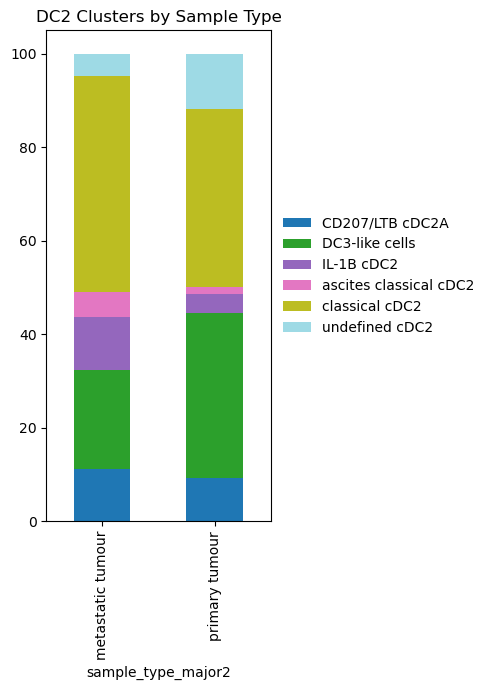

In [10]:
pd.crosstab(data_sub.obs["sample_type_major2"], data_sub.obs["cDC2_annotated"]).apply(
    lambda r: r / r.sum() * 100, axis=1
).plot.bar(stacked=True, figsize=(5,7), colormap="tab20")
plt.legend(bbox_to_anchor=(1, 0.5), loc="center left", frameon=False)
plt.title("DC2 Clusters by Sample Type")
plt.tight_layout()  
plt.savefig("barplot_DC2_new_clusters_sample_type.pdf", format="pdf", bbox_inches="tight")
plt.show()

### Separate data into the different subsets to be analysed

In [11]:
data_CD207 = data_sub[data_sub.obs["cDC2_annotated"] == "CD207/LTB cDC2A"]
data_IL1B = data_sub[data_sub.obs["cDC2_annotated"] == "IL-1B cDC2"]
data_ascites = data_sub[data_sub.obs["cDC2_annotated"] == "ascites classical cDC2"]
data_dc2 = data_sub[data_sub.obs["cDC2_annotated"] == "classical cDC2"]
data_dc3 = data_sub[data_sub.obs["cDC2_annotated"] == "DC3-like cells"]

In [12]:
cell_type_data = {
    "CD207/LTB cDC2": data_CD207,
    "IL-1B cDC2": data_IL1B,
    "Ascites classical DC2": data_ascites,
    "Classical cDC2":data_dc2,
    "DC3-like cells": data_dc3
}

### Import Hallmark gene pathways

Hallmark gene sets used here: (species = "Homo sapiens", collection = "C5", subcollection = "GO:BP")

In [13]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwaySets')
H_sets = pd.read_excel("hallmark_sets.xlsx", sheet_name=None)

In [14]:
# Change keys to be gene set name (the first value in the 'gs_name' column) instead of Sheet1 etc 
H_sets2 = {df["gs_name"].iloc[0]: df for _, df in H_sets.items()}
H_sets = H_sets2

# Result
print(H_sets.keys())

dict_keys(['HALLMARK_ADIPOGENESIS', 'HALLMARK_ALLOGRAFT_REJECTION', 'HALLMARK_ANDROGEN_RESPONSE', 'HALLMARK_ANGIOGENESIS', 'HALLMARK_APICAL_JUNCTION', 'HALLMARK_APICAL_SURFACE', 'HALLMARK_APOPTOSIS', 'HALLMARK_BILE_ACID_METABOLISM', 'HALLMARK_CHOLESTEROL_HOMEOSTASIS', 'HALLMARK_COAGULATION', 'HALLMARK_COMPLEMENT', 'HALLMARK_DNA_REPAIR', 'HALLMARK_E2F_TARGETS', 'HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION', 'HALLMARK_ESTROGEN_RESPONSE_EARLY', 'HALLMARK_ESTROGEN_RESPONSE_LATE', 'HALLMARK_FATTY_ACID_METABOLISM', 'HALLMARK_G2M_CHECKPOINT', 'HALLMARK_GLYCOLYSIS', 'HALLMARK_HEDGEHOG_SIGNALING', 'HALLMARK_HEME_METABOLISM', 'HALLMARK_HYPOXIA', 'HALLMARK_IL2_STAT5_SIGNALING', 'HALLMARK_IL6_JAK_STAT3_SIGNALING', 'HALLMARK_INFLAMMATORY_RESPONSE', 'HALLMARK_INTERFERON_ALPHA_RESPONSE', 'HALLMARK_INTERFERON_GAMMA_RESPONSE', 'HALLMARK_KRAS_SIGNALING_DN', 'HALLMARK_KRAS_SIGNALING_UP', 'HALLMARK_MITOTIC_SPINDLE', 'HALLMARK_MTORC1_SIGNALING', 'HALLMARK_MYC_TARGETS_V1', 'HALLMARK_MYC_TARGETS_V2', 'HALLMAR

Score each DC subset according to the Hallmark gene sets

In [15]:
# Iterate through each gene set in H_sets - CD207
for set_name, gene_set_df in H_sets.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_CD207, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets - IL1B DCs
for set_name, gene_set_df in H_sets.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_IL1B, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets - Ascites classical cDC2
for set_name, gene_set_df in H_sets.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_ascites, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets - Classical cDC2
for set_name, gene_set_df in H_sets.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_dc2, gene_list=gene_set, score_name=f"{set_name}_score")

    # Iterate through each gene set in H_sets - DC3 like cells
for set_name, gene_set_df in H_sets.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_dc3, gene_list=gene_set, score_name=f"{set_name}_score")

       'FABP4', 'GPAT4', 'LEP', 'MIGA2', 'MRAP', 'MTARC2', 'ORM1', 'SLC66A3',
       'SQOR'],
      dtype='object')
       'IL13', 'IL2', 'IL4', 'IL9', 'KRT1', 'MBL2', 'NOS2', 'PF4', 'RARS1',
       'TGFB1', 'WARS1'],
      dtype='object')
       'CLDN18', 'CLDN19', 'CLDN6', 'CLDN8', 'COL9A1', 'DMP1', 'DSC1', 'FLNC',
       'FYB1', 'KCNH2', 'KRT31', 'MAP3K20', 'NECTIN1', 'NECTIN2', 'NECTIN3',
       'NECTIN4', 'NHERF4', 'NRAP', 'PALS1', 'PECAM1', 'PPP2R2C', 'SLC30A3',
       'WNK4'],
      dtype='object')
       'CYP39A1', 'CYP7A1', 'CYP8B1', 'DIO1', 'GC', 'HAO1', 'HSD3B1', 'NR0B2',
       'NR1H4', 'NR1I2', 'RXRG', 'SERPINA6', 'SLC67A1', 'SLCO1A2', 'SOAT2',
       'TTR'],
      dtype='object')


/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'F11', 'F13B', 'F2', 'F9', 'FGA', 'FGG', 'GDA', 'GP9', 'HMGCS2',
       'HNF4A', 'HRG', 'LEFTY2', 'MBL2', 'MEP1A', 'MMP8', 'PECAM1', 'PF4',
       'PLG', 'PROZ', 'RGN'],
      dtype='object')
       'MMP12', 'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'FOXC2', 'LRRC15', 'MATN3', 'NID2', 'P3H1', 'POSTN', 'PRSS2', 'PTHLH',
       'RGS4', 'SCG2', 'SGCG', 'TGFB1', 'VEGFC'],
      dtype='object')
       'MINDY1', 'NHERF1', 'NPY1R', 'PLAAT3', 'RETREG1', 'SEMA3B', 'SLC1A1',
       'SOX3'],
      dtype='object')
       'GFUS', 'GJB3', 'HMGCS2', 'LARGE1', 'NHERF1', 'NPY1R', 'PCP4', 'PLAAT3',
       'SEMA3B', 'SERPINA5', 'SOX3', 'TH'],
      dtype='object')
       'CYP4A22', 'FABP1', 'FABP2', 'FMO1', 'GAD2', 'GAPDHS', 'H2AZ1', 'HAO2',
       'HMGCS2', 'KMT5A', 'MIX23', 'TDO2', 'XIST'],
      dtype='object')
       'KMT5A', 'KNL1', 'MAP3K20', 'NSD2', 'PRP4K', 'PTTG3P', 'TENT4A',
       'TGFB1'],
      dtype='object')
       'GFUS', 'GPR87', 'GYS2', 'LCT', 'LHX9', 'NOL3', 

/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'F11', 'F13B', 'F2', 'F9', 'FGA', 'FGG', 'GDA', 'GP9', 'HMGCS2',
       'HNF4A', 'HRG', 'LEFTY2', 'MBL2', 'MEP1A', 'MMP8', 'PECAM1', 'PF4',
       'PLG', 'PROZ', 'RGN'],
      dtype='object')
       'MMP12', 'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'FOXC2', 'LRRC15', 'MATN3', 'NID2', 'P3H1', 'POSTN', 'PRSS2', 'PTHLH',
       'RGS4', 'SCG2', 'SGCG', 'TGFB1', 'VEGFC'],
      dtype='object')
       'MINDY1', 'NHERF1', 'NPY1R', 'PLAAT3', 'RETREG1', 'SEMA3B', 'SLC1A1',
       'SOX3'],
      dtype='object')
       'GFUS', 'GJB3', 'HMGCS2', 'LARGE1', 'NHERF1', 'NPY1R', 'PCP4', 'PLAAT3',
       'SEMA3B', 'SERPINA5', 'SOX3', 'TH'],
      dtype='object')
       'CYP4A22', 'FABP1', 'FABP2', 'FMO1', 'GAD2', 'GAPDHS', 'H2AZ1', 'HAO2',
       'HMGCS2', 'KMT5A', 'MIX23', 'TDO2', 'XIST'],
      dtype='object')
       'KMT5A', 'KNL1', 'MAP3K20', 'NSD2', 'PRP4K', 'PTTG3P', 'TENT4A',
       'TGFB1'],
      dtype='object')
       'GFUS', 'GPR87', 'GYS2', 'LCT', 'LHX9', 'NOL3', 

/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'FOXC2', 'LRRC15', 'MATN3', 'NID2', 'P3H1', 'POSTN', 'PRSS2', 'PTHLH',
       'RGS4', 'SCG2', 'SGCG', 'TGFB1', 'VEGFC'],
      dtype='object')
       'MINDY1', 'NHERF1', 'NPY1R', 'PLAAT3', 'RETREG1', 'SEMA3B', 'SLC1A1',
       'SOX3'],
      dtype='object')
       'GFUS', 'GJB3', 'HMGCS2', 'LARGE1', 'NHERF1', 'NPY1R', 'PCP4', 'PLAAT3',
       'SEMA3B', 'SERPINA5', 'SOX3', 'TH'],
      dtype='object')
       'CYP4A22', 'FABP1', 'FABP2', 'FMO1', 'GAD2', 'GAPDHS', 'H2AZ1', 'HAO2',
       'HMGCS2', 'KMT5A', 'MIX23', 'TDO2', 'XIST'],
      dtype='object')
       'KMT5A', 'KNL1', 'MAP3K20', 'NSD2', 'PRP4K', 'PTTG3P', 'TENT4A',
       'TGFB1'],
      dtype='object')
       'GFUS', 'GPR87', 'GYS2', 'LCT', 'LHX9', 'NOL3', 'PFKFB1', 'PGLS',
       'RARS1'],
      dtype='object')
       'GYPE', 'H1-0', 'H4C3', 'HBBP1', 'HBD', 'HBQ1', 'HBZ', 'KEL', 'MARCHF2',
       'MARCHF8', 'PGLS', 'RHAG', 'SLC30A10', 'SLC4A1', 'SLC66A2', 'SPTA1',
       'TENT5C', 'TRIM10', 'TSPO2', 'TYR'],
      dtype='

/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'CLDN18', 'CLDN19', 'CLDN6', 'CLDN8', 'COL9A1', 'DMP1', 'DSC1', 'FLNC',
       'FYB1', 'KCNH2', 'KRT31', 'MAP3K20', 'NECTIN1', 'NECTIN2', 'NECTIN3',
       'NECTIN4', 'NHERF4', 'NRAP', 'PALS1', 'PECAM1', 'PPP2R2C', 'SLC30A3',
       'WNK4'],
      dtype='object')
       'CYP39A1', 'CYP7A1', 'CYP8B1', 'DIO1', 'GC', 'HAO1', 'HSD3B1', 'NR0B2',
       'NR1H4', 'NR1I2', 'RXRG', 'SERPINA6', 'SLC67A1', 'SLCO1A2', 'SOAT2',
       'TTR'],
      dtype='object')
       'F11', 'F13B', 'F2', 'F9', 'FGA', 'FGG', 'GDA', 'GP9', 'HMGCS2',
       'HNF4A', 'HRG', 'LEFTY2', 'MBL2', 'MEP1A', 'MMP8', 'PECAM1', 'PF4',
       'PLG', 'PROZ', 'RGN'],
      dtype='object')
       'MMP12', 'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'FOXC2', 'LRRC15', 'MATN3', 'NID2', 'P3H1', 'POSTN', 'PRSS2', 'PTHLH',
       'RGS4', 'SCG2', 'SGCG', 'TGFB1', 'VEGFC'],
      dtype='object')
       'MINDY1', 'NHERF1', 'NPY1R', 'PLAAT3', 'RETREG1', 'SEMA3B', 'SLC1A1',
       'SOX3'],
      dtype='object')
  

/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'CLDN18', 'CLDN19', 'CLDN6', 'CLDN8', 'COL9A1', 'DMP1', 'DSC1', 'FLNC',
       'FYB1', 'KCNH2', 'KRT31', 'MAP3K20', 'NECTIN1', 'NECTIN2', 'NECTIN3',
       'NECTIN4', 'NHERF4', 'NRAP', 'PALS1', 'PECAM1', 'PPP2R2C', 'SLC30A3',
       'WNK4'],
      dtype='object')
       'CYP39A1', 'CYP7A1', 'CYP8B1', 'DIO1', 'GC', 'HAO1', 'HSD3B1', 'NR0B2',
       'NR1H4', 'NR1I2', 'RXRG', 'SERPINA6', 'SLC67A1', 'SLCO1A2', 'SOAT2',
       'TTR'],
      dtype='object')
       'F11', 'F13B', 'F2', 'F9', 'FGA', 'FGG', 'GDA', 'GP9', 'HMGCS2',
       'HNF4A', 'HRG', 'LEFTY2', 'MBL2', 'MEP1A', 'MMP8', 'PECAM1', 'PF4',
       'PLG', 'PROZ', 'RGN'],
      dtype='object')
       'MMP12', 'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'FOXC2', 'LRRC15', 'MATN3', 'NID2', 'P3H1', 'POSTN', 'PRSS2', 'PTHLH',
       'RGS4', 'SCG2', 'SGCG', 'TGFB1', 'VEGFC'],
      dtype='object')
       'MINDY1', 'NHERF1', 'NPY1R', 'PLAAT3', 'RETREG1', 'SEMA3B', 'SLC1A1',
       'SOX3'],
      dtype='object')
  

### Import KEGG gene pathways

KEGG gene sets used here: (species = "human", collection = "C2", subcollection = "CP:KEGG_LEGACY")

In [16]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwaySets')
K_sets = pd.read_excel("kegg_sets.xlsx", sheet_name=None)

In [17]:
# Change keys to be gene set name (the first value in the 'gs_name' column) instead of Sheet1 etc 
K_sets2 = {df["gs_name"].iloc[0]: df for _, df in K_sets.items()}
K_sets = K_sets2

# Result
print(K_sets.keys())

dict_keys(['KEGG_ABC_TRANSPORTERS', 'KEGG_ACUTE_MYELOID_LEUKEMIA', 'KEGG_ADHERENS_JUNCTION', 'KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY', 'KEGG_ALANINE_ASPARTATE_AND_GLUTAMATE_METABOLISM', 'KEGG_ALDOSTERONE_REGULATED_SODIUM_REABSORPTION', 'KEGG_ALLOGRAFT_REJECTION', 'KEGG_ALPHA_LINOLENIC_ACID_METABOLISM', 'KEGG_ALZHEIMERS_DISEASE', 'KEGG_AMINO_SUGAR_AND_NUCLEOTIDE_SUGAR_METABOLISM', 'KEGG_AMINOACYL_TRNA_BIOSYNTHESIS', 'KEGG_AMYOTROPHIC_LATERAL_SCLEROSIS_ALS', 'KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION', 'KEGG_APOPTOSIS', 'KEGG_ARACHIDONIC_ACID_METABOLISM', 'KEGG_ARGININE_AND_PROLINE_METABOLISM', 'KEGG_ARRHYTHMOGENIC_RIGHT_VENTRICULAR_CARDIOMYOPATHY_ARVC', 'KEGG_ASCORBATE_AND_ALDARATE_METABOLISM', 'KEGG_ASTHMA', 'KEGG_AUTOIMMUNE_THYROID_DISEASE', 'KEGG_AXON_GUIDANCE', 'KEGG_B_CELL_RECEPTOR_SIGNALING_PATHWAY', 'KEGG_BASAL_CELL_CARCINOMA', 'KEGG_BASAL_TRANSCRIPTION_FACTORS', 'KEGG_BASE_EXCISION_REPAIR', 'KEGG_BETA_ALANINE_METABOLISM', 'KEGG_BIOSYNTHESIS_OF_UNSATURATED_FATTY_ACIDS', 'KEGG_BLADDE

Remove unnecessary KEGG sets

In [18]:
# Keys to include in new dictionary
keys_include = ["KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY",
"KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION",
"KEGG_APOPTOSIS",
"KEGG_CALCIUM_SIGNALING_PATHWAY",
"KEGG_CELL_ADHESION_MOLECULES_CAMS",
"KEGG_CHEMOKINE_SIGNALING_PATHWAY",
"KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION",
"KEGG_CYTOSOLIC_DNA_SENSING_PATHWAY",
"KEGG_ENDOCYTOSIS",
"KEGG_FATTY_ACID_METABOLISM",
"KEGG_FC_GAMMA_R_MEDIATED_PHAGOCYTOSIS",
"KEGG_GLYCOLYSIS_GLUCONEOGENESIS",
"KEGG_JAK_STAT_SIGNALING_PATHWAY",
"KEGG_LEUKOCYTE_TRANSENDOTHELIAL_MIGRATION",
"KEGG_MAPK_SIGNALING_PATHWAY",
"KEGG_NOD_LIKE_RECEPTOR_SIGNALING_PATHWAY",
"KEGG_NOTCH_SIGNALING_PATHWAY",
"KEGG_OXIDATIVE_PHOSPHORYLATION",
"KEGG_PROTEASOME",
"KEGG_PROTEIN_EXPORT",
"KEGG_TGF_BETA_SIGNALING_PATHWAY",
"KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY",
"KEGG_TYROSINE_METABOLISM",
"KEGG_UBIQUITIN_MEDIATED_PROTEOLYSIS",
"KEGG_VEGF_SIGNALING_PATHWAY"]

In [19]:
# create a new dictionary with select keys (pathway sets)
K_sets_sub = {key: K_sets[key] for key in keys_include if key in K_sets}

# Display the new dictionary
K_sets_sub

{'KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY':    gene_symbol  ncbi_gene     ensembl_gene db_gene_symbol  db_ncbi_gene  \
 0        ACACB         32  ENSG00000076555          ACACB            32   
 1        ACSL1       2180  ENSG00000151726          ACSL1          2180   
 2        ACSL3       2181  ENSG00000123983          ACSL3          2181   
 3        ACSL4       2182  ENSG00000068366          ACSL4          2182   
 4        ACSL5      51703  ENSG00000197142          ACSL5         51703   
 ..         ...        ...              ...            ...           ...   
 62         TNF       7124  ENSG00000232810            TNF          7124   
 63    TNFRSF1A       7132  ENSG00000067182       TNFRSF1A          7132   
 64    TNFRSF1B       7133  ENSG00000028137       TNFRSF1B          7133   
 65       TRADD       8717  ENSG00000102871          TRADD          8717   
 66       TRAF2       7186  ENSG00000127191          TRAF2          7186   
 
     db_ensembl_gene  source_gene   gs_id  \
 

Score each DC subset according to the KEGG pathway sets

In [20]:
# Iterate through each gene set in K_sets_sub - CD207
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_CD207, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - IL1B DCs
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_IL1B, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - Ascites classical cDC2
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_ascites, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - Classical cDC2
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_dc2, gene_list=gene_set, score_name=f"{set_name}_score")

    # Iterate through each gene set in K_sets_sub - DC3 like cells
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_dc3, gene_list=gene_set, score_name=f"{set_name}_score")
     

       'PPARGC1A', 'PRKAG3', 'RXRG'],
      dtype='object')
       'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7',
       'IFNA8', 'KIR2DL1', 'KIR2DL2', 'KIR2DL3', 'KIR2DL4', 'KIR2DL5A',
       'KIR2DS1', 'KIR2DS3', 'KIR2DS4', 'KIR2DS5', 'KIR3DL3', 'KLRC3'],
      dtype='object')
       'ATP2B3', 'AVPR1A', 'AVPR1B', 'BDKRB1', 'CACNA1B', 'CACNA1E', 'CACNA1H',
       'CACNA1I', 'CACNA1S', 'CALML6', 'CAMK2A', 'CCKAR', 'CCKBR', 'CHP2',
       'CHRM1', 'CHRM2', 'CHRM5', 'DRD1', 'DRD5', 'GRM1', 'GRM5', 'GRPR',
       'HTR2A', 'HTR2C', 'HTR4', 'HTR5A', 'HTR6', 'LHCGR', 'MYLK2', 'MYLK3',
       'NOS2', 'P2RX2', 'P2RX3', 'P2RX6', 'PLCZ1', 'PLN', 'PPP3R2', 'PRKACG',
       'PTGFR', 'SLC25A31', 'TACR3', 'TBXA2R', 'TRHR', 'VDAC2P5'],
      dtype='object')
       'CLDN6', 'CLDN8', 'HLA-DRB3', 'HLA-DRB4', 'NECTIN1', 'NECTIN2',
       'NECTIN3', 'NLGN4X', 'PECAM1'],
      dtype='object')
       'CCL27', 'CCL3L3', 'CCR8', 'CXCL8', 'GNB3', 'GNG13', 'GNG3', 'GNGT1',
       'GRK1', 'GRK2

## First, calculate the pathway differences for all 5 cell types

# Run KEGG pathway first

In [21]:
results = []

for cell_type, adata in cell_type_data.items():

    obs_df = adata.obs.copy()

    # Keep only primary and metastatic
    obs_df = obs_df[
        obs_df["sample_type_major2"].isin(
            ["primary tumour", "metastatic tumour"]
        )
    ]

    for gene_set in K_sets_sub.keys():

        score_col = f"{gene_set}_score"

        if score_col not in obs_df.columns:
            continue

        # Remove missing values
        data = obs_df[
            ["sample_type_major2", score_col]
        ].dropna()

        primary = data.loc[
            data["sample_type_major2"] == "primary tumour",
            score_col
        ]

        metastatic = data.loc[
            data["sample_type_major2"] == "metastatic tumour",
            score_col
        ]

        if len(primary) == 0 or len(metastatic) == 0:
            continue

        # Welch t-test
        stat, p_value = ttest_ind(
            primary,
            metastatic,
            equal_var=False
        )

        mean_primary = primary.mean()
        mean_metastatic = metastatic.mean()

        results.append({
            "Cell Type": cell_type,
            "Gene Set": gene_set,
            "Primary Mean": mean_primary,
            "Metastatic Mean": mean_metastatic,
            "Difference": mean_metastatic - mean_primary,
            "P-value": p_value
        })

results_df = pd.DataFrame(results)

In [22]:
data_CD207.obs.columns.tolist()

['nCount_RNA',
 'nFeature_RNA',
 'sample_type',
 'cancer_type',
 'patient_id',
 'sample_id',
 'percent.mt',
 'site',
 'sample_type_major',
 'cancer_subtype',
 'integration_id',
 'ident',
 'dataset_id',
 'n_genes_by_counts',
 'log1p_n_genes_by_counts',
 'total_counts',
 'log1p_total_counts',
 'pct_counts_in_top_50_genes',
 'pct_counts_in_top_100_genes',
 'pct_counts_in_top_200_genes',
 'pct_counts_in_top_500_genes',
 'total_counts_mt',
 'log1p_total_counts_mt',
 'pct_counts_mt',
 'S_score',
 'G2M_score',
 'keep_or_remove',
 'leiden',
 'celltype',
 'leiden_DC',
 'leiden_DC_v2',
 'exclude_annots',
 'leiden_M',
 'Technology',
 'NR_annotations_simple',
 'sample_type_major2',
 'cancer_with_H',
 'cancer_broadest',
 'patient_treatment',
 'Guimaraes_DC2_FCER1A',
 'Guimaraes_DC2_AREG',
 'Guimaraes_Cheng_DC2_CD207/CD1A',
 'Guimaraes_DC3_CD14',
 'Guimaraes_DC4_FCGR3A',
 'Guimaraes_DC_CXCL2',
 'Cheng_DC2_CXCR4',
 'Cheng_DC2_IL1B',
 'Cheng_DC2_FCN1',
 'Cheng_DC2_ISG15',
 'Cheng_DC2_CXCL9',
 'DC3_sig

In [23]:
print(results_df.shape)
print(results_df.columns.tolist())
print(results_df.head())

(125, 6)
['Cell Type', 'Gene Set', 'Primary Mean', 'Metastatic Mean', 'Difference', 'P-value']
        Cell Type                                  Gene Set  Primary Mean  \
0  CD207/LTB cDC2      KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY     -0.050387   
1  CD207/LTB cDC2  KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION      0.789366   
2  CD207/LTB cDC2                            KEGG_APOPTOSIS     -0.021016   
3  CD207/LTB cDC2            KEGG_CALCIUM_SIGNALING_PATHWAY     -0.014863   
4  CD207/LTB cDC2         KEGG_CELL_ADHESION_MOLECULES_CAMS      0.208844   

   Metastatic Mean  Difference       P-value  
0        -0.051604   -0.001218  7.056396e-01  
1         0.923372    0.134006  1.187315e-18  
2        -0.004225    0.016791  9.977539e-07  
3        -0.009622    0.005241  6.494130e-03  
4         0.251290    0.042446  3.031161e-14  


Correct the p-values for multiple testing

In [24]:
results_df["FDR"] = multipletests(
    results_df["P-value"],
    method="fdr_bh"
)[1]

Create a significance label

In [25]:
def significance_label(fdr):
    if fdr < 0.0001:
        return "****"
    elif fdr < 0.001:
        return "***"
    elif fdr < 0.01:
        return "**"
    elif fdr < 0.05:
        return "*"
    else:
        return ""

results_df["Significance"] = results_df["FDR"].apply(
    significance_label
)

Make the summary heatmap

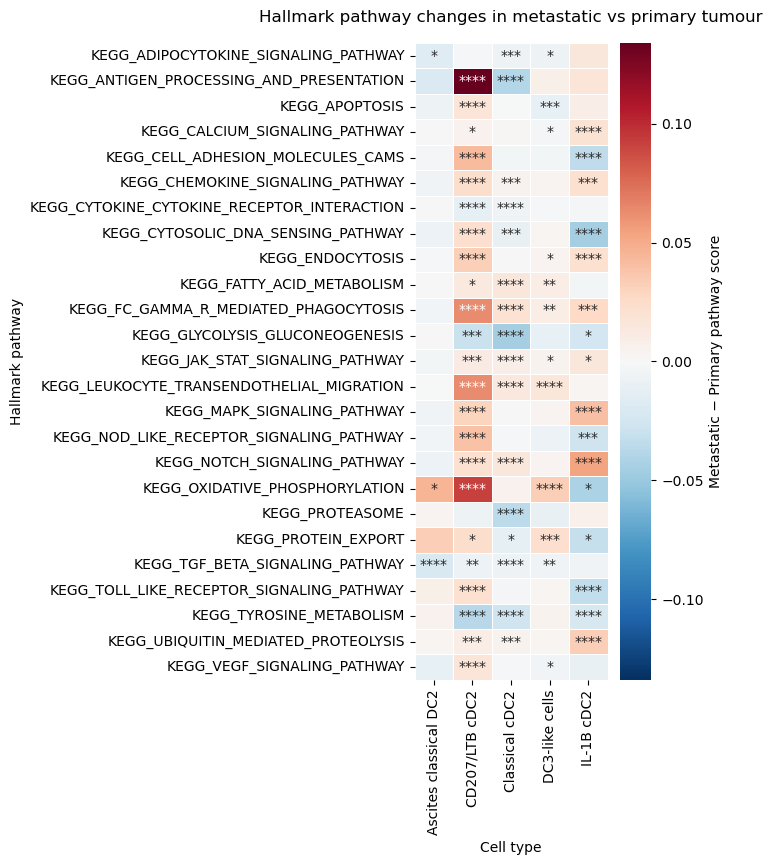

In [ ]:
# Convert to matrix
heatmap_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Difference"
)

# Significance matrix
significance_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Significance"
)

# Create figure
plt.figure(
    figsize=(
        7,
        max(8, len(heatmap_data) * 0.35)
    )
)

# Make colour scale symmetric around zero
max_abs = np.nanmax(np.abs(heatmap_data.values))

ax = sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    annot=significance_data,
    fmt="",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Metastatic − Primary pathway score"
    }
)

plt.xlabel("Cell type")
plt.ylabel("KEGG pathway")

plt.title(
    "KEGG pathway changes in metastatic vs primary tumour",
    pad=15
)

plt.tight_layout()
plt.show()

In [27]:
# OPTIONAL: Order pathways by average effect across cell types
pathway_order = (
    heatmap_data
    .mean(axis=1)
    .sort_values()
    .index
)

heatmap_data = heatmap_data.loc[pathway_order]
significance_data = significance_data.loc[pathway_order]

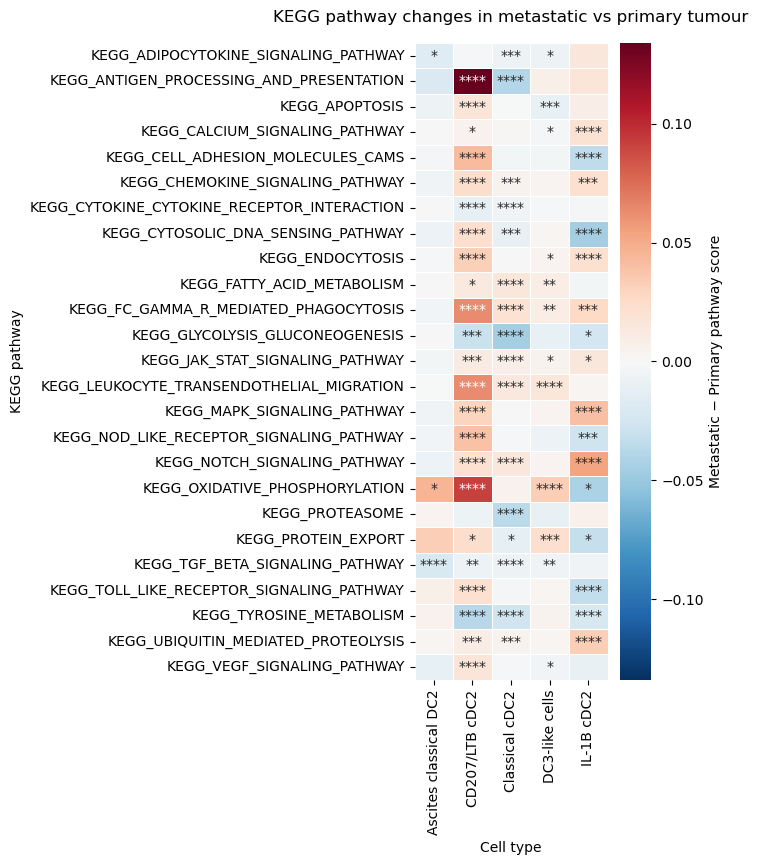

In [28]:
# Convert to matrix
heatmap_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Difference"
)

# Significance matrix
significance_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Significance"
)

# Create figure
plt.figure(
    figsize=(
        7,
        max(8, len(heatmap_data) * 0.35)
    )
)

# Make colour scale symmetric around zero
max_abs = np.nanmax(np.abs(heatmap_data.values))

ax = sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    annot=significance_data,
    fmt="",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Metastatic − Primary pathway score"
    }
)

plt.xlabel("Cell type")
plt.ylabel("KEGG pathway")

plt.title(
    "KEGG pathway changes in metastatic vs primary tumour",
    pad=15
)

plt.tight_layout()
plt.show()

# Run Hallmark pathway

In [29]:
del results
del results_df

In [30]:
results = []

for cell_type, adata in cell_type_data.items():

    obs_df = adata.obs.copy()

    # Keep only primary and metastatic
    obs_df = obs_df[
        obs_df["sample_type_major2"].isin(
            ["primary tumour", "metastatic tumour"]
        )
    ]

    for gene_set in H_sets.keys():

        score_col = f"{gene_set}_score"

        if score_col not in obs_df.columns:
            continue

        # Remove missing values
        data = obs_df[
            ["sample_type_major2", score_col]
        ].dropna()

        primary = data.loc[
            data["sample_type_major2"] == "primary tumour",
            score_col
        ]

        metastatic = data.loc[
            data["sample_type_major2"] == "metastatic tumour",
            score_col
        ]

        if len(primary) == 0 or len(metastatic) == 0:
            continue

        # Welch t-test
        stat, p_value = ttest_ind(
            primary,
            metastatic,
            equal_var=False
        )

        mean_primary = primary.mean()
        mean_metastatic = metastatic.mean()

        results.append({
            "Cell Type": cell_type,
            "Gene Set": gene_set,
            "Primary Mean": mean_primary,
            "Metastatic Mean": mean_metastatic,
            "Difference": mean_metastatic - mean_primary,
            "P-value": p_value
        })

results_df = pd.DataFrame(results)

In [31]:
print(results_df.shape)
print(results_df.columns.tolist())
print(results_df.head())

(250, 6)
['Cell Type', 'Gene Set', 'Primary Mean', 'Metastatic Mean', 'Difference', 'P-value']
        Cell Type                      Gene Set  Primary Mean  \
0  CD207/LTB cDC2         HALLMARK_ADIPOGENESIS      0.076730   
1  CD207/LTB cDC2  HALLMARK_ALLOGRAFT_REJECTION      0.276274   
2  CD207/LTB cDC2    HALLMARK_ANDROGEN_RESPONSE      0.080644   
3  CD207/LTB cDC2         HALLMARK_ANGIOGENESIS     -0.024746   
4  CD207/LTB cDC2      HALLMARK_APICAL_JUNCTION      0.044067   

   Metastatic Mean  Difference       P-value  
0         0.092434    0.015704  3.730570e-07  
1         0.337912    0.061638  4.402572e-29  
2         0.114515    0.033871  3.931265e-18  
3        -0.041336   -0.016590  1.947595e-03  
4         0.044697    0.000631  7.622561e-01  


Correct the p values for multiple testing

In [32]:
results_df["FDR"] = multipletests(
    results_df["P-value"],
    method="fdr_bh"
)[1]

In [33]:
def significance_label(fdr):
    if fdr < 0.0001:
        return "****"
    elif fdr < 0.001:
        return "***"
    elif fdr < 0.01:
        return "**"
    elif fdr < 0.05:
        return "*"
    else:
        return ""

results_df["Significance"] = results_df["FDR"].apply(
    significance_label
)

Make a summary heatmap

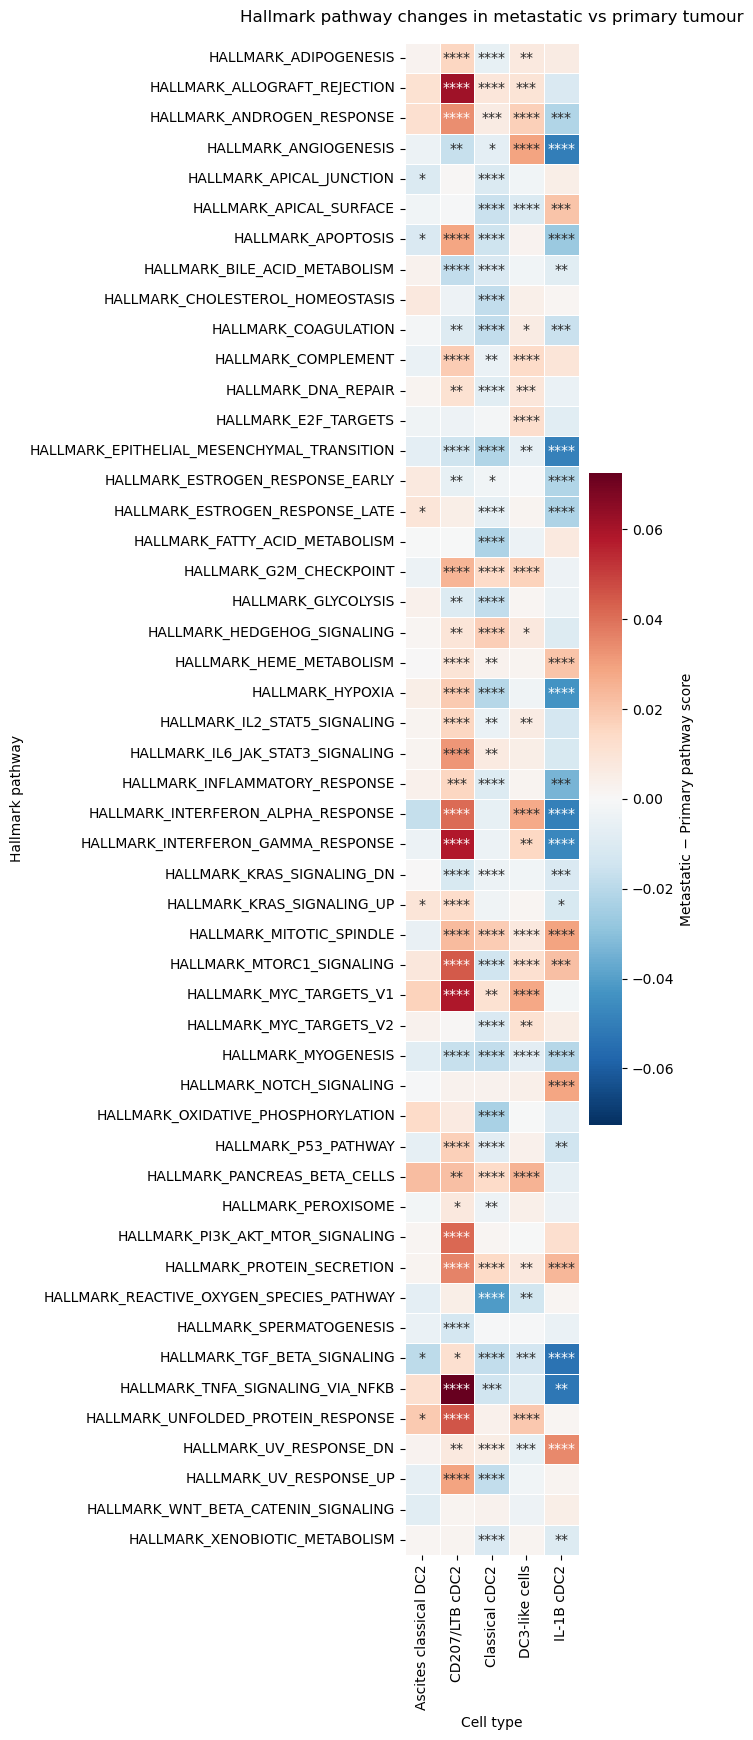

In [34]:
# Convert to matrix
heatmap_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Difference"
)

# Significance matrix
significance_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Significance"
)

# Create figure
plt.figure(
    figsize=(
        7,
        max(8, len(heatmap_data) * 0.35)
    )
)

# Make colour scale symmetric around zero
max_abs = np.nanmax(np.abs(heatmap_data.values))

ax = sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    annot=significance_data,
    fmt="",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Metastatic − Primary pathway score"
    }
)

plt.xlabel("Cell type")
plt.ylabel("Hallmark pathway")

plt.title(
    "Hallmark pathway changes in metastatic vs primary tumour",
    pad=15
)

plt.tight_layout()
plt.show()

### Subset Hallmark genes

In [ ]:
# Keys to include in new dictionary
keys_include = ["KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY",
"KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION",
"KEGG_APOPTOSIS",
"KEGG_CALCIUM_SIGNALING_PATHWAY",
"KEGG_CELL_ADHESION_MOLECULES_CAMS",
"KEGG_CHEMOKINE_SIGNALING_PATHWAY",
"KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION",
"KEGG_CYTOSOLIC_DNA_SENSING_PATHWAY",
"KEGG_ENDOCYTOSIS",
"KEGG_FATTY_ACID_METABOLISM",
"KEGG_FC_GAMMA_R_MEDIATED_PHAGOCYTOSIS",
"KEGG_GLYCOLYSIS_GLUCONEOGENESIS",
"KEGG_JAK_STAT_SIGNALING_PATHWAY",
"KEGG_LEUKOCYTE_TRANSENDOTHELIAL_MIGRATION",
"KEGG_MAPK_SIGNALING_PATHWAY",
"KEGG_NOD_LIKE_RECEPTOR_SIGNALING_PATHWAY",
"KEGG_NOTCH_SIGNALING_PATHWAY",
"KEGG_OXIDATIVE_PHOSPHORYLATION",
"KEGG_PROTEASOME",
"KEGG_PROTEIN_EXPORT",
"KEGG_TGF_BETA_SIGNALING_PATHWAY",
"KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY",
"KEGG_TYROSINE_METABOLISM",
"KEGG_UBIQUITIN_MEDIATED_PROTEOLYSIS",
"KEGG_VEGF_SIGNALING_PATHWAY"]